Importing the Libraries

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


Load the dataset

In [8]:

diabetes_dataset = pd.read_csv("diabetes.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", diabetes_dataset.shape)

diabetes_dataset.head()


Dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Explore the data

In [9]:

# Check the column names and data types
print("Dataset information:")
diabetes_dataset.info()

# Check for missing values
print("\nMissing values:")
print(diabetes_dataset.isnull().sum())

# Check outcome distribution
print("\nOutcome counts:")
print(diabetes_dataset["Outcome"].value_counts())

# Statistical summary
diabetes_dataset.describe()



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Separate features and target

In [10]:

# Input features
X = diabetes_dataset.drop(columns=["Outcome"]).copy()

# Target variable
Y = diabetes_dataset["Outcome"].copy()

# In this dataset, zero may represent a missing measurement
missing_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[missing_cols] = X[missing_cols].replace(0, np.nan)

print("Features shape:", X.shape)
print("Target shape:", Y.shape)


Features shape: (768, 8)
Target shape: (768,)


Split the dataset

In [11]:

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    stratify=Y,
    random_state=2
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", Y_train.shape)
print("Testing target:", Y_test.shape)


Training features: (614, 8)
Testing features: (154, 8)
Training target: (614,)
Testing target: (154,)


Train the Logistic Regression model

In [12]:

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, Y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


Calculate training accuracy

In [13]:

X_train_prediction = model.predict(X_train)

training_data_accuracy = accuracy_score(
    Y_train,
    X_train_prediction
)

print(
    "Accuracy score on training data:",
    round(training_data_accuracy * 100, 2), "%"
)


Accuracy score on training data: 78.5 %


Calculate test accuracy

In [14]:

X_test_prediction = model.predict(X_test)

test_data_accuracy = accuracy_score(
    Y_test,
    X_test_prediction
)

print(
    "Accuracy score on test data:",
    round(test_data_accuracy * 100, 2), "%"
)


Accuracy score on test data: 74.03 %


Generate the confusion matrix

Confusion Matrix:
[[88 12]
 [28 26]]


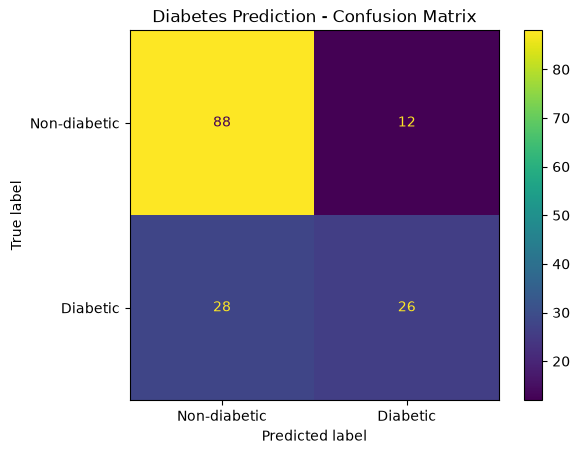

In [15]:

Y_pred = model.predict(X_test)

cm = confusion_matrix(Y_test, Y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-diabetic", "Diabetic"]
)

display.plot()
plt.title("Diabetes Prediction - Confusion Matrix")
plt.show()


0 --> Non-Diabetic

1 --> Diabetic

Classification report

In [16]:

print("Classification Report:")
print(classification_report(
    Y_test,
    Y_pred,
    target_names=["Non-diabetic", "Diabetic"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

Non-diabetic       0.76      0.88      0.81       100
    Diabetic       0.68      0.48      0.57        54

    accuracy                           0.74       154
   macro avg       0.72      0.68      0.69       154
weighted avg       0.73      0.74      0.73       154



Make a sample prediction

In [17]:

# Example input: 8 diagnostic health features
input_data = (5, 166, 72, 19, 175, 25.8, 0.587, 51)

# Convert input into a DataFrame
input_data_df = pd.DataFrame(
    [input_data],
    columns=X.columns
)

# Predict using the trained pipeline
prediction = model.predict(input_data_df)

print("Prediction:", prediction)

if prediction[0] == 0:
    print("The model predicts: Non-diabetic")
else:
    print("The model predicts: Diabetic")


Prediction: [1]
The model predicts: Diabetic
